# Visualize the Self-RAG graph

This notebook imports the compiled LangGraph app from `src/self-rag.py`, prints its Mermaid diagram, and renders it as a PNG. Run it from any working directory.

In [1]:
import importlib.util
from pathlib import Path
from IPython.display import Image, Markdown, display

search_roots = [Path.cwd(), *Path.cwd().parents]
module_path = next(
    root / 'src' / 'self-rag.py'
    for root in search_roots
    if (root / 'src' / 'self-rag.py').exists()
)
spec = importlib.util.spec_from_file_location('self_rag_graph', module_path)
self_rag = importlib.util.module_from_spec(spec)
spec.loader.exec_module(self_rag)
app = self_rag.app
print(f'Loaded graph from: {module_path}')

Loaded graph from: /Users/aaravverma/Desktop/self-RAG_project/src/self-rag.py


In [2]:
graph = app.get_graph()
mermaid = graph.draw_mermaid()
display(Markdown(f'```mermaid\n{mermaid}\n```'))

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	decide_retrieval(decide_retrieval)
	generate_direct(generate_direct)
	retrieve(retrieve)
	is_relevant(is_relevant)
	generate_from_context(generate_from_context)
	no_answer_found(no_answer_found)
	is_sup(is_sup)
	revise_answer(revise_answer)
	is_use(is_use)
	rewrite_question(rewrite_question)
	__end__([<p>__end__</p>]):::last
	__start__ --> decide_retrieval;
	decide_retrieval -.-> generate_direct;
	decide_retrieval -.-> retrieve;
	generate_from_context --> is_sup;
	is_relevant -.-> generate_from_context;
	is_relevant -.-> no_answer_found;
	is_relevant -.-> rewrite_question;
	is_sup -. &nbsp;accept_answer&nbsp; .-> is_use;
	is_sup -.-> no_answer_found;
	is_sup -.-> revise_answer;
	is_use -. &nbsp;END&nbsp; .-> __end__;
	is_use -.-> no_answer_found;
	is_use -.-> rewrite_question;
	retrieve --> is_relevant;
	revise_answer --> is_sup;
	rewrite_question --> retrieve;
	generate_direct --> __end__;
	no_answer_found --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

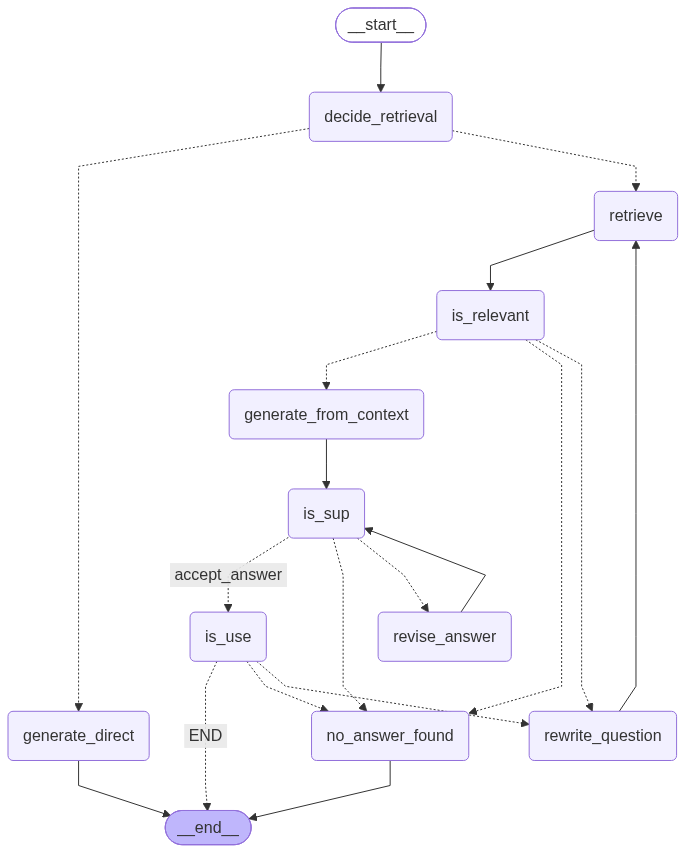

In [3]:
# Render the Mermaid diagram to PNG using LangGraph's Mermaid service.
# This cell needs network access. The Mermaid source above remains available offline.
png = graph.draw_mermaid_png()
display(Image(png))